30 June 2019

# *LabOrch*  $~$ Reconstruction

The goal of this reconstruction is to implement here, the algorithms in [Rose and Hetrick](https://www.mitpressjournals.org/doi/abs/10.1162/comj.2009.33.1.32)

The first question is which library/package to use for audio processing. [This page](https://realpython.com/playing-and-recording-sound-python/) is relatively new (May 2019), and has many suggestions.

## Read in Bank data

I have found various directories from the previous work (under `LabOrch2009/`). One of them (`VAw_S2013/Orch/`) contains 983 FFT files.  
Not sure if that is an exhaustive set of the originals, but other directories have fewer (in the 800s).

Let's see if we can read one of these in and manipulate it, ideally all the way to playback.

In [1]:
import numpy as np

srcfile = '../OldFFTBank/obo-e4-ord-mf.nbb'

f = np.fromfile(srcfile, dtype='float32')

In [2]:
f

array([0.001, 0.   , 0.   , ..., 0.   , 0.   , 0.   ], dtype=float32)

In [3]:
len(f)

2048

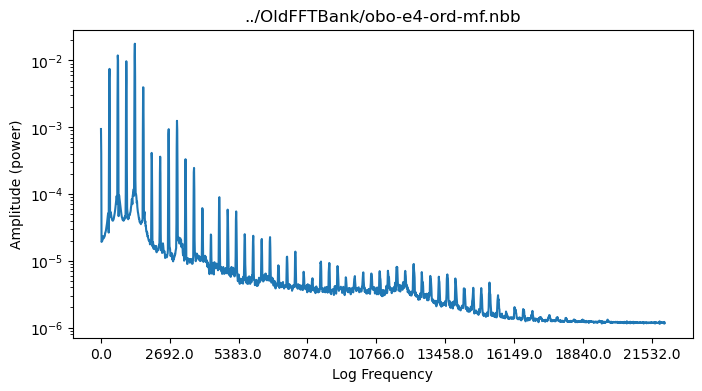

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,4))
plt.plot(range(len(f)), f, '-')
#plt.xscale('log')
plt.yscale('log')

plt.title(srcfile)
plt.ylabel('Amplitude (power)')
plt.xlabel('Log Frequency')

xt = np.array([0,250,500,750,1000,1250,1500,1750,2000])

labs = [s.decode('utf-8') for s in np.round((10.766 * xt)).astype('S')]
plt.xticks(xt,labs);

OK. I can read in a `.nbb` file, and plot it. Here the *log(f)* is shown.

`.nbb` files are made of 2048, 32-bit (4-byte), floats. 

---

$$-\infty-$$

---

# Playback of a numpy array

Following: https://realpython.com/playing-and-recording-sound-python/

Need to install `simpleaudio`.

In [9]:
!pip install simpleaudio

### Example: create and play 220 Hz tone

In [21]:
import simpleaudio as sa

frequency = 220  # Our played note will be 440 Hz
fs = 44100  # 44100 samples per second
seconds = 3  # Note duration of 3 seconds

# Generate array with seconds*sample_rate steps, ranging between 0 and seconds
t = np.linspace(0, seconds, seconds * fs, False)

# Generate a 440 Hz sine wave
note = np.sin(frequency * t * 2 * np.pi)

# Ensure that highest value is in 16-bit range
audio = note * (2**15 - 1) / np.max(np.abs(note))
# Convert to 16-bit data
audio = audio.astype(np.int16)

# Start playback
play_obj = sa.play_buffer(audio, 1, 2, fs)

# Wait for playback to finish before exiting
play_obj.wait_done()

Works.

---

## Transform Oboe FFT from f-space back to t-space

Using `scipy.fftpack` https://docs.scipy.org/doc/scipy/reference/tutorial/fftpack.html#one-dimensional-discrete-fourier-transforms

as it seems to have better performance.

In [24]:
# Example from docs

from scipy.fftpack import rfft, irfft, fft, ifft

x = np.array([0.0, 1.0, 2.0, 1.0, 0.0, -1.0, -2.0, -1.0])
print('x', x)
Xf = fft(x)
print('Xf',Xf)

xx = ifft(Xf)
print('xx', xx)

x [ 0.  1.  2.  1.  0. -1. -2. -1.]
Xf [0.-0.j    0.-6.828j 0.-0.j    0.+1.172j 0.-0.j    0.-1.172j 0.+0.j
 0.+6.828j]
xx [ 0.+0.j  1.+0.j  2.+0.j  1.+0.j  0.+0.j -1.+0.j -2.-0.j -1.+0.j]


Inverse includes division by volume of the array.

In [25]:
f

array([0.001, 0.   , 0.   , ..., 0.   , 0.   , 0.   ], dtype=float32)

In [26]:
ft = ifft(f)

In [27]:
ft

array([0.-0.j, 0.+0.j, 0.+0.j, ..., 0.-0.j, 0.-0.j, 0.-0.j],
      dtype=complex64)

In [28]:
np.real(ft)

array([0., 0., 0., ..., 0., 0., 0.], dtype=float32)

In [29]:
len(ft)

2048

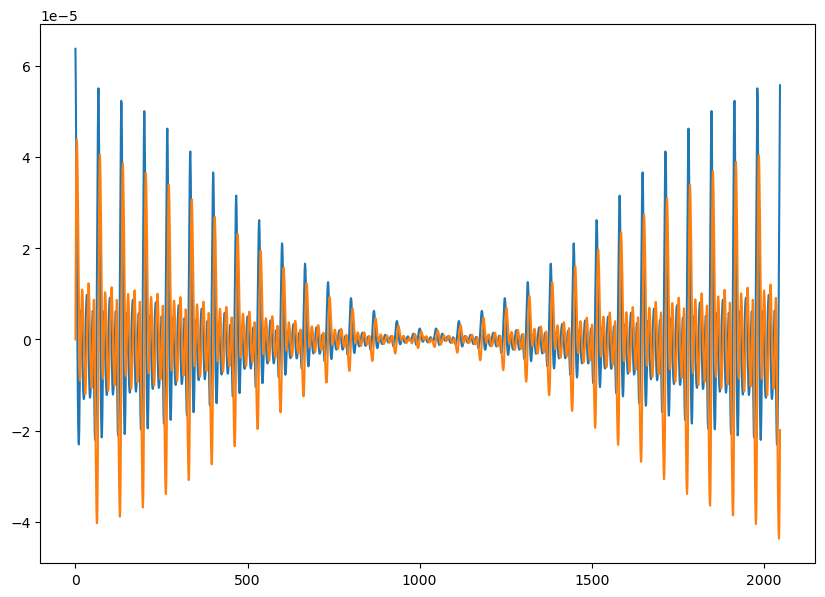

In [30]:
plt.plot(np.arange(len(ft)), np.real(ft))
plt.plot(np.arange(len(ft)), np.imag(ft))

Nope, doesn't look right.

---

* Went back and read the FFT chapter in Numerical Recipies.

The bank files we have are *power spectra*: the square of the FFT at each positive frequency.

Since the time-domain sound function is real, $h(t) \in \mathbb{R} \Rightarrow H(-f) = H^*(f)$.

Here are my notes on deconstructing an power spectrum (freq-domain) back to a sound (time-domain) array.

<img src='../Imgs/power_fft_bujo.jpg' width=800>

---

So, to make a *sound* (t) file from a *power* (f) file, we need to

* Take the square root
* Unfold: fill out the second half of the file of size 2N by *reversing and appending* the first half. 

In [31]:
len(f)

2048

In [32]:
f

array([0.001, 0.   , 0.   , ..., 0.   , 0.   , 0.   ], dtype=float32)

In [33]:
fsq = np.sqrt(f)
fsq

array([0.031, 0.02 , 0.004, ..., 0.001, 0.001, 0.001], dtype=float32)

In [34]:
fsqrv = np.flip(fsq[:-1], axis=0)
fsqrv

array([0.001, 0.001, 0.001, ..., 0.004, 0.02 , 0.031], dtype=float32)

In [35]:
len(fsqrv)

2047

In [36]:
ffull = np.append(fsq, fsqrv)

In [37]:
len(ffull)

4095

In [38]:
ffull = np.insert(ffull, 0, 0.0)

In [39]:
len(ffull)

4096

In [40]:
ft = ifft(ffull)

In [41]:
len(ft)

4096

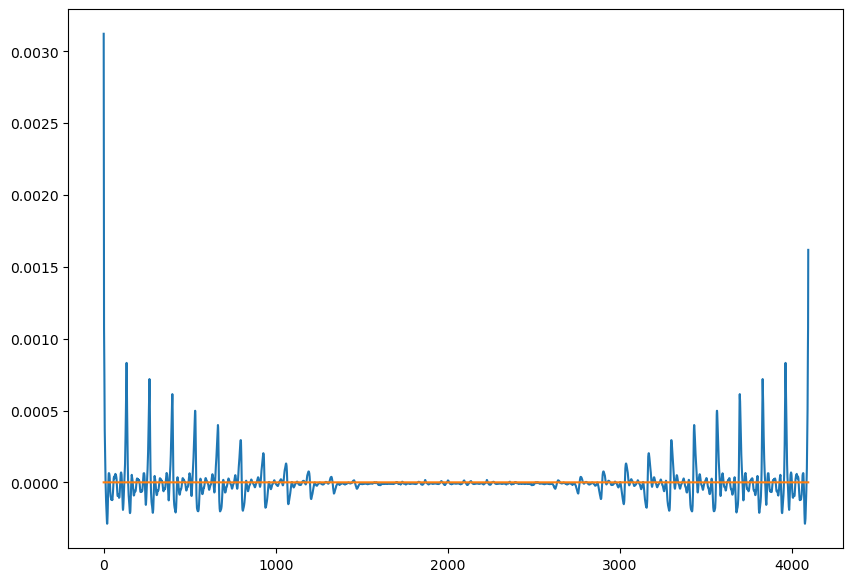

In [42]:
plt.plot(np.arange(len(ft)), np.real(ft))
plt.plot(np.arange(len(ft)), np.imag(ft))

Still not right.

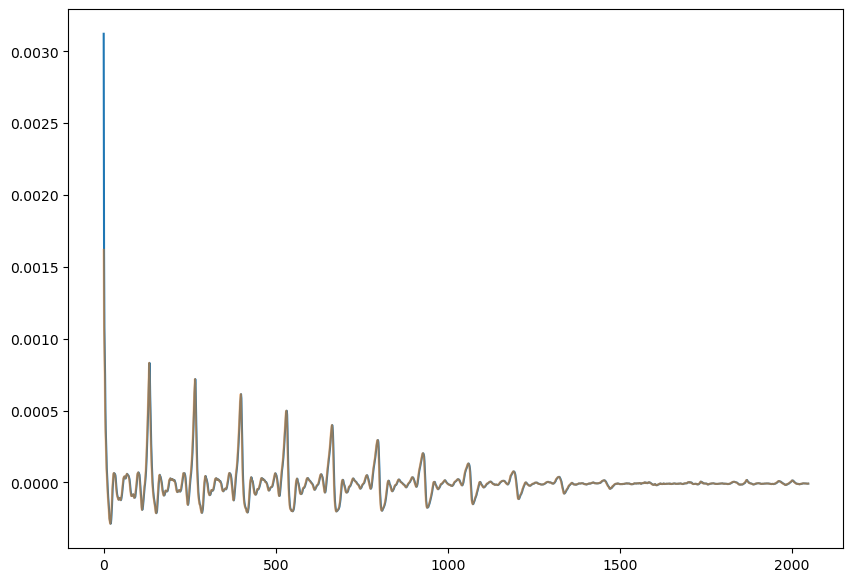

In [43]:
plt.plot(np.arange(len(ft)/2), np.real(ft)[:2048])
plt.plot(np.arange(len(ft)/2), np.real(ft)[4097:2047:-1], alpha=0.5)


When the power spectrum is computed to make the NBB banks sound files, we that the magnitude of the complex FFT.  
This truncates the information we have for doing the reconstructon of the *time-domain* sound from the power spectrum.

Working on this problem...